# 01 - Feed-forward network (MLP) for regression and classification
Wine Quality dataset (red and white wines)

In the ML report the best model was a random forest (RMSE 0.680 for regression, macro F1 0.604 for
the Low / Medium / High classification). Here we try to solve the **same two problems** with a
feed-forward neural network (multilayer perceptron, MLP) written in PyTorch, and we compare the
results using the **same 5 outer folds** as in the ML report.

The code of the network and of the training loop is in `utils.py`, so the other notebooks can
reuse it. It follows the PyTorch quickstart notebook seen in class.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from sklearn.model_selection import KFold, StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score, f1_score,
                             accuracy_score, balanced_accuracy_score, confusion_matrix)

from utils import *

set_style()
torch.set_num_threads(4)
np.random.seed(SEED)
torch.manual_seed(SEED)

## 1. Data

We use exactly the same preparation as in the ML report: red and white wines together, duplicated
rows removed, and the two targets:

* Regression: the `quality` score.
* Classification: Low (quality ≤ 5), Medium (= 6) and High (≥ 7).

The inputs are the 11 physicochemical variables plus `is_red`.

In [2]:
wine = load_wine()
X = wine[FEATURES].to_numpy()
y = wine["quality"].to_numpy().astype(float)
c = wine["class_id"].to_numpy()

print("X:", X.shape)
print(wine["quality_class"].value_counts().reindex(CLASS_ORDER))

X: (5320, 12)
quality_class
Low       1988
Medium    2323
High      1009
Name: count, dtype: int64


## 2. The network

A feed-forward network is a stack of fully connected (`Linear`) layers with a non-linear activation
(ReLU) between them. The last layer has 1 output for regression and 3 outputs (one per class) for
classification. We also add a small dropout (10%) after each hidden layer.

Two things are important with neural networks that were not so important with the random forest:

* **Scaling.** The inputs have very different scales (density ≈ 1, total SO2 up to 400), so we
  standardise them with a `StandardScaler` fitted only on the training part of each fold. For
  regression we also standardise the target and transform the predictions back at the end.
* **Validation set.** We keep 15% of the training part of each fold as validation set. It is used
  for early stopping and to choose the architecture. The test fold is never used for training.

In [3]:
example = MLP(n_in=X.shape[1], hidden=(64, 32), n_out=1, dropout=0.1)
print(example)
print("Trainable parameters:", count_parameters(example))

MLP(
  (body): Sequential(
    (0): Linear(in_features=12, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.1, inplace=False)
  )
  (head): Linear(in_features=32, out_features=1, bias=True)
)
Trainable parameters: 2945


## 3. Training

`train_model` (in `utils.py`) does mini-batch training (batch size 64) with the Adam optimiser
(learning rate 0.001). After every epoch it computes the loss on the validation set and keeps the
weights of the best epoch. If the validation loss does not improve for 20 epochs, training stops
(early stopping).

Losses:
* Regression: mean squared error (`MSELoss`).
* Classification: cross-entropy (`CrossEntropyLoss`, it applies the softmax internally).

## 4. Protocol

* Outer loop: the same 5 folds as in the ML report (`KFold` for regression, `StratifiedKFold` for
  classification, both with `random_state=42`).
* Inside every fold we try three architectures and keep the one with the lowest validation loss.
  This is the same idea as the inner loop of the nested cross-validation.

In [4]:
ARCHS = {"Small (32)": (32,), "Medium (64-32)": (64, 32), "Large (128-64-32)": (128, 64, 32)}
DROPOUT = 0.1

mse = nn.MSELoss()
ce = nn.CrossEntropyLoss()

def reg_loss(out, yb):
    return mse(out.squeeze(1), yb)

def clf_loss(out, yb):
    return ce(out, yb)

def rmse(a, b):
    return np.sqrt(mean_squared_error(a, b))

def choose_and_train(Xtr, Ytr, Xval, Yval, n_out, loss_fn):
    # trains the three architectures and returns the one with the lowest validation loss
    best = None
    for name, hidden in ARCHS.items():
        torch.manual_seed(SEED)
        model = MLP(Xtr.shape[1], hidden, n_out, DROPOUT)
        hist = train_model(model, Xtr, Ytr, Xval, Yval, loss_fn)
        if best is None or min(hist["val"]) < best["val"]:
            best = {"val": min(hist["val"]), "name": name, "model": model, "hist": hist}
    return best

### 4.1 Regression

In [5]:
outer_reg = KFold(n_splits=5, shuffle=True, random_state=SEED)
reg_rows, reg_curves = [], {}
oof_reg = np.zeros(len(y))

for fold, (train_idx, test_idx) in enumerate(outer_reg.split(X), start=1):
    tr, val = train_test_split(train_idx, test_size=0.15, random_state=SEED)
    scaler = StandardScaler().fit(X[tr])
    y_mean, y_std = y[tr].mean(), y[tr].std()

    Xtr, Xval, Xte = (to_tensor(scaler.transform(X[i])) for i in (tr, val, test_idx))
    ytr, yval = (to_tensor((y[i] - y_mean) / y_std) for i in (tr, val))

    best = choose_and_train(Xtr, (ytr,), Xval, (yval,), 1, reg_loss)
    model = best["model"].eval()
    with torch.no_grad():
        pred = model(Xte).squeeze(1).numpy() * y_std + y_mean
    oof_reg[test_idx] = pred
    reg_curves[fold] = best["hist"]
    reg_rows.append({"fold": fold, "architecture": best["name"], "epochs": best["hist"]["best_epoch"],
                     "RMSE": rmse(y[test_idx], pred), "MAE": mean_absolute_error(y[test_idx], pred),
                     "R2": r2_score(y[test_idx], pred)})
    print(reg_rows[-1])

reg_folds = pd.DataFrame(reg_rows)
reg_folds.to_csv(RES_DIR / "mlp_regression_folds.csv", index=False)
reg_folds.round(3)

{'fold': 1, 'architecture': 'Medium (64-32)', 'epochs': 22, 'RMSE': np.float64(0.6745060898632281), 'MAE': 0.5346385933192775, 'R2': 0.39489884327970215}


{'fold': 2, 'architecture': 'Medium (64-32)', 'epochs': 28, 'RMSE': np.float64(0.6766985743098382), 'MAE': 0.5360225641906893, 'R2': 0.3932092219240819}


{'fold': 3, 'architecture': 'Large (128-64-32)', 'epochs': 26, 'RMSE': np.float64(0.698145433493605), 'MAE': 0.5411638322248062, 'R2': 0.36174166047205947}


{'fold': 4, 'architecture': 'Large (128-64-32)', 'epochs': 13, 'RMSE': np.float64(0.7106972059138187), 'MAE': 0.554842762056673, 'R2': 0.35217522924983413}


{'fold': 5, 'architecture': 'Medium (64-32)', 'epochs': 40, 'RMSE': np.float64(0.7166460301267251), 'MAE': 0.558779690640165, 'R2': 0.3662294925539471}


,fold,architecture,epochs,RMSE,MAE,R2
0,1,Medium (64-32),22,0.675,0.535,0.395
1,2,Medium (64-32),28,0.677,0.536,0.393
2,3,Large (128-64-32),26,0.698,0.541,0.362
3,4,Large (128-64-32),13,0.711,0.555,0.352
4,5,Medium (64-32),40,0.717,0.559,0.366


### 4.2 Classification

In [6]:
outer_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
clf_rows, clf_curves = [], {}
oof_clf = np.zeros(len(c), dtype=int)

for fold, (train_idx, test_idx) in enumerate(outer_clf.split(X, c), start=1):
    tr, val = train_test_split(train_idx, test_size=0.15, random_state=SEED, stratify=c[train_idx])
    scaler = StandardScaler().fit(X[tr])

    Xtr, Xval, Xte = (to_tensor(scaler.transform(X[i])) for i in (tr, val, test_idx))
    ctr, cval = (torch.tensor(c[i], dtype=torch.long) for i in (tr, val))

    best = choose_and_train(Xtr, (ctr,), Xval, (cval,), 3, clf_loss)
    model = best["model"].eval()
    with torch.no_grad():
        pred = model(Xte).argmax(1).numpy()
    oof_clf[test_idx] = pred
    clf_curves[fold] = best["hist"]
    clf_rows.append({"fold": fold, "architecture": best["name"], "epochs": best["hist"]["best_epoch"],
                     "Macro F1": f1_score(c[test_idx], pred, average="macro"),
                     "Accuracy": accuracy_score(c[test_idx], pred),
                     "Balanced acc": balanced_accuracy_score(c[test_idx], pred)})
    print(clf_rows[-1])

clf_folds = pd.DataFrame(clf_rows)
clf_folds.to_csv(RES_DIR / "mlp_classification_folds.csv", index=False)
clf_folds.round(3)

{'fold': 1, 'architecture': 'Large (128-64-32)', 'epochs': 27, 'Macro F1': 0.5858744058142709, 'Accuracy': 0.606203007518797, 'Balanced acc': 0.5788646060237528}


{'fold': 2, 'architecture': 'Large (128-64-32)', 'epochs': 40, 'Macro F1': 0.5901559956640651, 'Accuracy': 0.6156015037593985, 'Balanced acc': 0.5807844202805309}


{'fold': 3, 'architecture': 'Large (128-64-32)', 'epochs': 22, 'Macro F1': 0.5596653099092124, 'Accuracy': 0.5874060150375939, 'Balanced acc': 0.5471536940992662}


{'fold': 4, 'architecture': 'Large (128-64-32)', 'epochs': 32, 'Macro F1': 0.5690831478575248, 'Accuracy': 0.6043233082706767, 'Balanced acc': 0.5552655151758777}


{'fold': 5, 'architecture': 'Medium (64-32)', 'epochs': 36, 'Macro F1': 0.5910548579723504, 'Accuracy': 0.6118421052631579, 'Balanced acc': 0.5763017424680633}


,fold,architecture,epochs,Macro F1,Accuracy,Balanced acc
0,1,Large (128-64-32),27,0.586,0.606,0.579
1,2,Large (128-64-32),40,0.590,0.616,0.581
2,3,Large (128-64-32),22,0.560,0.587,0.547
3,4,Large (128-64-32),32,0.569,0.604,0.555
4,5,Medium (64-32),36,0.591,0.612,0.576


## 5. Learning curves

Training and validation loss of the selected network in the first fold. The dashed line is the
epoch with the lowest validation loss (the weights we keep).

Figure saved -> ../results/figures/mlp_learning_curves.png


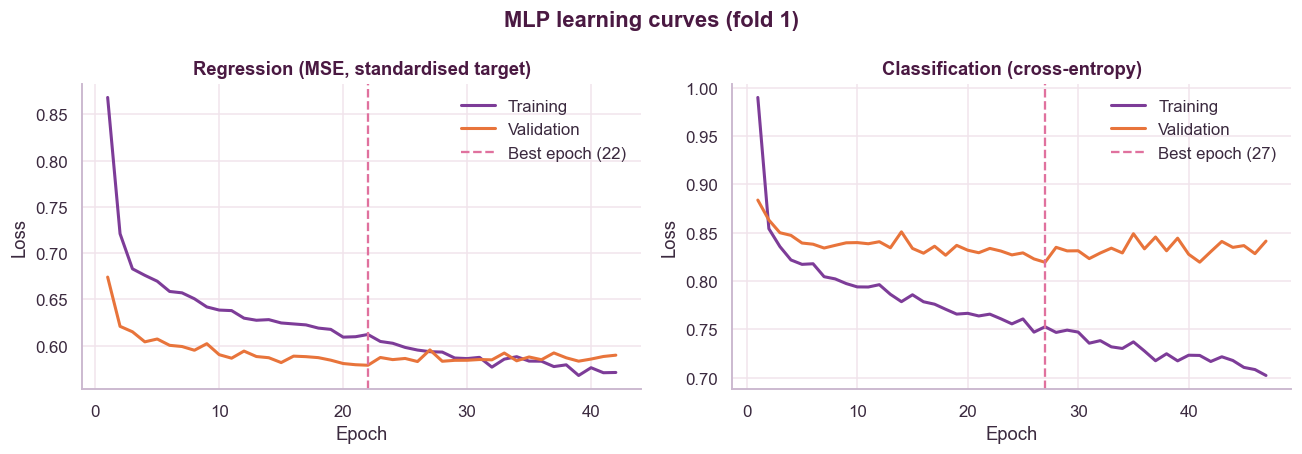

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, curves, title in zip(axes, [reg_curves, clf_curves],
                             ["Regression (MSE, standardised target)", "Classification (cross-entropy)"]):
    h = curves[1]
    ax.plot(range(1, len(h["train"]) + 1), h["train"], color=PURPLE, lw=2, label="Training")
    ax.plot(range(1, len(h["val"]) + 1), h["val"], color=ORANGE, lw=2, label="Validation")
    ax.axvline(h["best_epoch"], color=PINK, ls="--", lw=1.5, label=f"Best epoch ({h['best_epoch']})")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.set_title(title)
    ax.legend()
fig.suptitle("MLP learning curves (fold 1)", color=PLUM, fontweight="semibold")
fig.tight_layout()
save(fig, "mlp_learning_curves.png")
plt.show()

## 6. Comparison with the ML models

We load the nested cross-validation results of the ML report (same folds, same wines).

In [8]:
ml_reg = pd.read_csv(DATA_DIR / "ml_results" / "regression_nested_summary.csv")
ml_clf = pd.read_csv(DATA_DIR / "ml_results" / "classification_nested_summary.csv")

reg_cmp = pd.concat([
    ml_reg[["Model", "RMSE mean", "RMSE std", "R2 mean"]],
    pd.DataFrame([{"Model": "MLP (this report)", "RMSE mean": reg_folds.RMSE.mean(),
                   "RMSE std": reg_folds.RMSE.std(), "R2 mean": reg_folds.R2.mean()}]),
]).sort_values("RMSE mean").reset_index(drop=True)

clf_cmp = pd.concat([
    ml_clf[["Model", "Macro F1 mean", "Macro F1 std", "Accuracy mean"]],
    pd.DataFrame([{"Model": "MLP (this report)", "Macro F1 mean": clf_folds["Macro F1"].mean(),
                   "Macro F1 std": clf_folds["Macro F1"].std(),
                   "Accuracy mean": clf_folds["Accuracy"].mean()}]),
]).sort_values("Macro F1 mean", ascending=False).reset_index(drop=True)

reg_cmp.to_csv(RES_DIR / "comparison_regression.csv", index=False)
clf_cmp.to_csv(RES_DIR / "comparison_classification.csv", index=False)
display(reg_cmp.round(3))
display(clf_cmp.round(3))

,Model,RMSE mean,RMSE std,R2 mean
0,Random forest,0.680,0.014,0.401
1,Gradient boosting,0.689,0.018,0.384
2,SVR,0.694,0.015,0.377
3,MLP (this report),0.695,0.019,0.374
4,KNN,0.704,0.018,0.358
5,Lasso,0.733,0.016,0.305
6,Linear regression,0.733,0.016,0.305
7,Ridge,0.733,0.016,0.304
8,Decision tree,0.750,0.013,0.271
9,Mean baseline,0.880,0.015,-0.004


,Model,Macro F1 mean,Macro F1 std,Accuracy mean
0,Random forest,0.604,0.012,0.617
1,Gradient boosting,0.592,0.012,0.610
2,SVM,0.583,0.013,0.611
3,KNN,0.579,0.016,0.599
4,MLP (this report),0.579,0.014,0.605
5,Logistic regression,0.557,0.007,0.587
6,Decision tree,0.532,0.011,0.558
7,Majority baseline,0.203,0.000,0.437


Figure saved -> ../results/figures/mlp_vs_ml.png


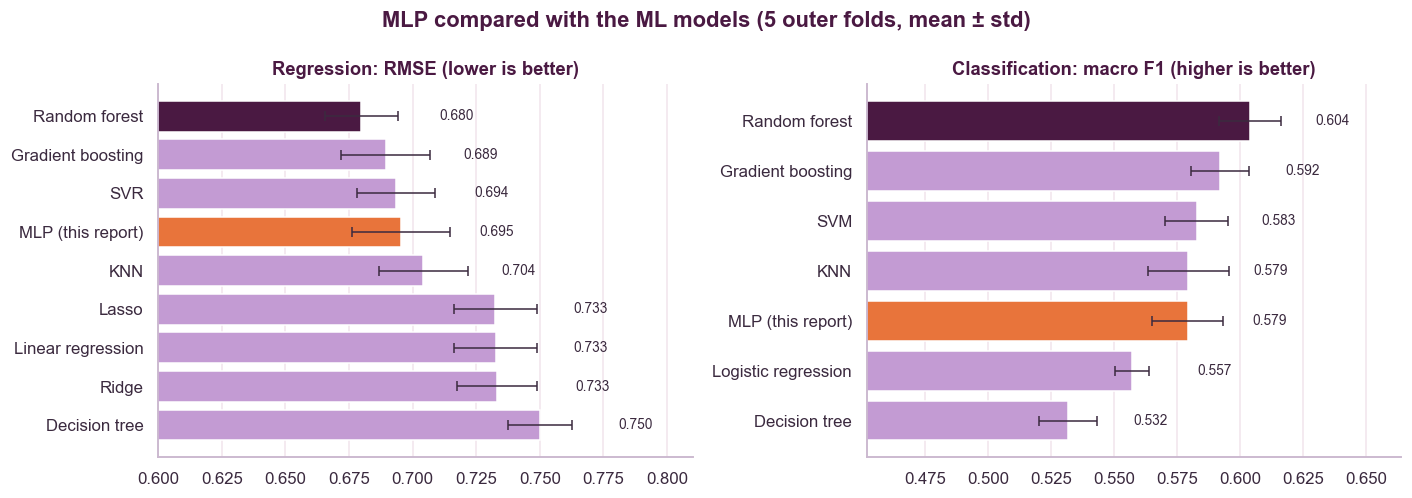

In [9]:
def bar_colors(models):
    return [ORANGE if m.startswith("MLP") else PLUM if m == "Random forest" else LILAC for m in models]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, df, col, std, title in [
        (axes[0], reg_cmp[reg_cmp.Model != "Mean baseline"], "RMSE mean", "RMSE std", "Regression: RMSE (lower is better)"),
        (axes[1], clf_cmp[clf_cmp.Model != "Majority baseline"], "Macro F1 mean", "Macro F1 std", "Classification: macro F1 (higher is better)")]:
    ax.barh(df.Model, df[col], xerr=df[std], color=bar_colors(df.Model), edgecolor="white",
            error_kw=dict(ecolor=INK, lw=1, capsize=3))
    for i, v in enumerate(df[col]):
        ax.text(v + df[std].max() * 1.6, i, f"{v:.3f}", va="center", fontsize=9)
    ax.invert_yaxis()
    lo, hi = df[col].min(), df[col].max()
    ax.set_xlim(lo - 0.08, hi + 0.06)
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
fig.suptitle("MLP compared with the ML models (5 outer folds, mean ± std)", color=PLUM, fontweight="semibold")
fig.tight_layout()
save(fig, "mlp_vs_ml.png")
plt.show()

## 7. Confusion matrix of the MLP

Out-of-fold predictions: every wine is predicted once by a network that did not see it.

Figure saved -> ../results/figures/mlp_confusion_matrix.png


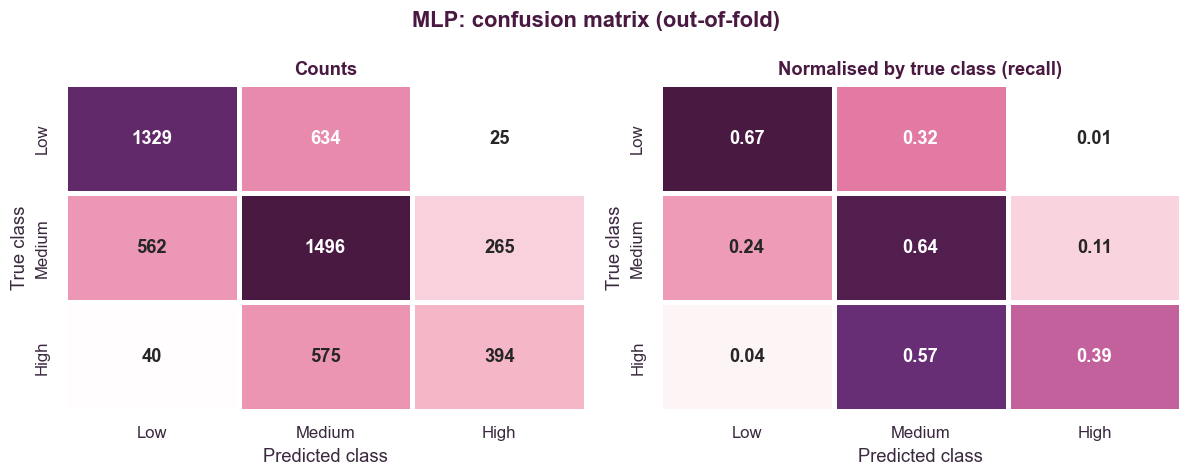

In [10]:
cm = confusion_matrix(c, oof_clf)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, m, fmt, title in [(axes[0], cm, "d", "Counts"), (axes[1], cm_norm, ".2f", "Normalised by true class (recall)")]:
    sns.heatmap(m, annot=True, fmt=fmt, cmap=CMAP_SEQ, cbar=False, linewidths=2, linecolor="white",
                xticklabels=CLASS_ORDER, yticklabels=CLASS_ORDER, ax=ax, annot_kws={"weight": "bold"})
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.set_title(title)
fig.suptitle("MLP: confusion matrix (out-of-fold)", color=PLUM, fontweight="semibold")
fig.tight_layout()
save(fig, "mlp_confusion_matrix.png")
plt.show()

In [11]:
print("Regression     : RMSE %.3f (%.3f), MAE %.3f, R2 %.3f" % (reg_folds.RMSE.mean(), reg_folds.RMSE.std(),
                                                             reg_folds.MAE.mean(), reg_folds.R2.mean()))
print("Classification : macro F1 %.3f (%.3f), accuracy %.3f, balanced acc %.3f" % (
    clf_folds["Macro F1"].mean(), clf_folds["Macro F1"].std(), clf_folds.Accuracy.mean(), clf_folds["Balanced acc"].mean()))
print("Architectures chosen (reg):", reg_folds.architecture.value_counts().to_dict())
print("Architectures chosen (clf):", clf_folds.architecture.value_counts().to_dict())

Regression     : RMSE 0.695 (0.019), MAE 0.545, R2 0.374
Classification : macro F1 0.579 (0.014), accuracy 0.605, balanced acc 0.568
Architectures chosen (reg): {'Medium (64-32)': 3, 'Large (128-64-32)': 2}
Architectures chosen (clf): {'Large (128-64-32)': 4, 'Medium (64-32)': 1}


## Summary

* The MLP learns the problem (it is much better than the baselines), but it does not beat the
  random forest of the ML report. It is at the level of the SVM / KNN models.
* Early stopping stops the training after a few dozen epochs, so the network does not overfit.
* As in the ML report, the hardest class is Medium, which is between the other two.